<a href="https://colab.research.google.com/github/vpfjt567/Skin_Care_team_project/blob/main/Untitled1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

from google.colab import drive

drive.mount('/content/drive')


Mounted at /content/drive


In [2]:
import os
DATA_PATH = "/content/drive/MyDrive/data/data"

TRAIN_PATH = os.path.join(DATA_PATH, "Training")
VAL_PATH = os.path.join(DATA_PATH, "Validation")

print("Training 폴더:", os.listdir(TRAIN_PATH)[:5])
print("Validation 폴더:", os.listdir(VAL_PATH)[:5])

Training 폴더: ['Actinic_Keratosis', 'Basal_Cell_Carcinoma', 'hemangioma', 'Melanocytic_nevus', 'Dermatofibroma']
Validation 폴더: ['Actinic_Keratosis', 'verruca', 'Melanocytic_nevus', 'Lentigo', 'Squamous_Cell_Carcinoma']


In [3]:
import torch

print("GPU 사용 가능:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU 이름:", torch.cuda.get_device_name(0))
else:
    print("CPU로 학습해야 합니다.")

GPU 사용 가능: True
GPU 이름: NVIDIA RTX PRO 6000 Blackwell Server Edition


In [4]:
import torch
import torchvision
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# 이미지 전처리
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# 데이터셋 불러오기
train_dataset = datasets.ImageFolder(
    root=TRAIN_PATH,
    transform=transform
)

val_dataset = datasets.ImageFolder(
    root=VAL_PATH,
    transform=transform
)

# 클래스 확인
print("클래스 수:", len(train_dataset.classes))
print("클래스 목록:", train_dataset.classes)

print("Training 이미지:", len(train_dataset))
print("Validation 이미지:", len(val_dataset))

클래스 수: 15
클래스 목록: ['Actinic_Keratosis', 'Basal_Cell_Carcinoma', 'Bowen_disease', 'Dermatofibroma', 'Lentigo', 'Malignant_melanoma', 'Melanocytic_nevus', 'Milium', 'Pyogenic_granuloma', 'Sebaceous_hyperplasia', 'Seborrheic_keratosis', 'Squamous_Cell_Carcinoma', 'epidermal_cyst', 'hemangioma', 'verruca']
Training 이미지: 12000
Validation 이미지: 1500


In [5]:
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Training 배치 수:", len(train_loader))
print("Validation 배치 수:", len(val_loader))

Training 배치 수: 375
Validation 배치 수: 47


In [6]:
images, labels = next(iter(train_loader))

print("이미지 크기:", images.shape)
print("레이블 크기:", labels.shape)
print("GPU 이동 전:", images.device)

이미지 크기: torch.Size([32, 3, 224, 224])
레이블 크기: torch.Size([32])
GPU 이동 전: cpu


In [7]:
import torch.nn as nn
from torchvision.models import resnet18, ResNet18_Weights

# GPU 설정
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ImageNet 사전학습 ResNet18 불러오기
model = resnet18(weights=ResNet18_Weights.DEFAULT)

# 마지막 분류층을 15개 클래스로 변경
num_features = model.fc.in_features
model.fc = nn.Linear(num_features, 15)

# 모델 전체를 학습 가능하도록 설정
for param in model.parameters():
    param.requires_grad = True

# GPU로 모델 이동
model = model.to(device)

print("사용 장치:", device)
print("분류 클래스:", model.fc.out_features)
print("학습 가능 파라미터:", sum(p.numel() for p in model.parameters() if p.requires_grad))

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 206MB/s]

사용 장치: cuda
분류 클래스: 15
학습 가능 파라미터: 11184207


In [8]:
import torch.optim as optim

# 손실 함수
criterion = nn.CrossEntropyLoss()

# Optimizer
optimizer = optim.Adam(
    model.parameters(),
    lr=0.0001
)

# 학습 설정
EPOCHS = 10

print("Loss Function:", criterion)
print("Optimizer:", optimizer)
print("Learning Rate:", optimizer.param_groups[0]["lr"])
print("Epochs:", EPOCHS)

Loss Function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0001
    maximize: False
    weight_decay: 0
)
Learning Rate: 0.0001
Epochs: 10


In [9]:
import time
import copy
from tqdm.auto import tqdm

# 최고 성능 모델 기록
best_val_acc = 0.0
history = []

# Google Drive에 모델 저장
SAVE_PATH = "/content/drive/MyDrive/resnet18_best.pth"

start_time = time.time()

for epoch in range(EPOCHS):

    # =========================
    # 1. Training
    # =========================
    model.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    train_bar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS} [Train]")

    for images, labels in train_bar:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)
        train_total += labels.size(0)
        train_correct += (predicted == labels).sum().item()

    train_loss /= train_total
    train_acc = 100 * train_correct / train_total

    # =========================
    # 2. Validation
    # =========================
    model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        val_bar = tqdm(val_loader, desc=f"Epoch {epoch+1}/{EPOCHS} [Val]")

        for images, labels in val_bar:

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss /= val_total
    val_acc = 100 * val_correct / val_total

    # =========================
    # 3. 결과 출력 및 저장
    # =========================
    print(f"\nEpoch [{epoch+1}/{EPOCHS}]")
    print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}%")
    print(f"Val Loss:   {val_loss:.4f} | Val Acc:   {val_acc:.2f}%")

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_acc": train_acc,
        "val_loss": val_loss,
        "val_acc": val_acc
    })

    # Validation Accuracy가 가장 높은 모델 저장
    if val_acc > best_val_acc:
        best_val_acc = val_acc

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "best_val_acc": best_val_acc,
            "classes": train_dataset.classes
        }, SAVE_PATH)

        print(f"Best model 저장 완료! ({best_val_acc:.2f}%)")

# =========================
# 4. 전체 학습 시간
# =========================
total_time = time.time() - start_time

print("\n===== 학습 완료 =====")
print(f"총 학습 시간: {total_time / 60:.2f}분")
print(f"최고 Validation Accuracy: {best_val_acc:.2f}%")
print(f"모델 저장 위치: {SAVE_PATH}")

Epoch 1/10 [Train]:   0%|          | 0/375 [00:00<?, ?it/s]

Epoch 1/10 [Val]:   0%|          | 0/47 [00:00<?, ?it/s]


Epoch [1/10]
Train Loss: 0.1556 | Train Acc: 96.74%
Val Loss:   0.0131 | Val Acc:   99.73%
Best model 저장 완료! (99.73%)


Epoch 2/10 [Train]:   0%|          | 0/375 [00:00<?, ?it/s]

Epoch 2/10 [Val]:   0%|          | 0/47 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79a4bd476b60>
Exception ignored in: Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
<function _MultiProcessingDataLoaderIter.__del__ at 0x79a4bd476b60>    
self._shutdown_workers()Traceback (most recent call last):

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
        self._shutdown_workers()if w.is_alive():

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
        if w.is_alive():assert self._parent_pid == os.getpid(), 'can only test a child process'

AssertionError  File "/usr/lib/python3.13/multiprocessing/proce

... (27 outputs left out)

Epoch 10/10 [Train]:   0%|          | 0/375 [00:00<?, ?it/s]

<function _MultiProcessingDataLoaderIter.__del__ at 0x79a4bd476b60>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    Exception ignored in: self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
<function _MultiProcessingDataLoaderIter.__del__ at 0x79a4bd476b60>    
if w.is_alive():Traceback (most recent call last):

  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    assert self._parent_pid == os.getpid(), 'can only test a child process'    
self._shutdown_workers()AssertionError
:   File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
can only test a child process
    if w.is_alive():
  File "/usr/lib/python3.13/multiproces

Epoch 10/10 [Val]:   0%|          | 0/47 [00:00<?, ?it/s]


Epoch [10/10]
Train Loss: 0.0015 | Train Acc: 99.97%
Val Loss:   0.0159 | Val Acc:   99.60%

===== 학습 완료 =====
총 학습 시간: 46.84분
최고 Validation Accuracy: 99.93%
모델 저장 위치: /content/drive/MyDrive/resnet18_best.pth


In [10]:
import pandas as pd

history_df = pd.DataFrame(history)

display(history_df)

,epoch,train_loss,train_acc,val_loss,val_acc
0,1,0.155578,96.741667,0.013145,99.733333
1,2,0.015702,99.650000,0.050357,98.466667
2,3,0.014302,99.650000,0.006012,99.800000
3,4,0.010795,99.750000,0.010184,99.666667
4,5,0.010009,99.758333,0.027443,98.933333
5,6,0.011970,99.641667,0.010503,99.733333
6,7,0.005682,99.841667,0.003860,99.933333
7,8,0.010350,99.675000,0.023754,99.266667
8,9,0.005529,99.875000,0.004172,99.800000
9,10,0.001546,99.966667,0.015850,99.600000


In [11]:
import torch

print("GPU 사용 가능:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU 이름:", torch.cuda.get_device_name(0))

GPU 사용 가능: True
GPU 이름: NVIDIA RTX PRO 6000 Blackwell Server Edition


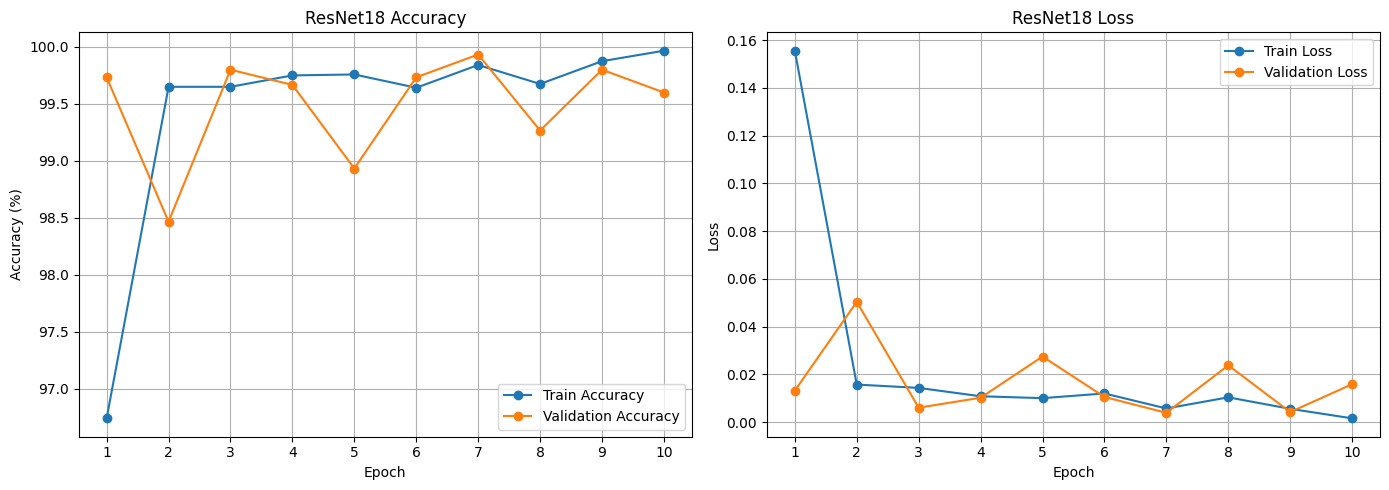

In [12]:
import matplotlib.pyplot as plt

epochs = [item["epoch"] for item in history]
train_acc = [item["train_acc"] for item in history]
val_acc = [item["val_acc"] for item in history]
train_loss = [item["train_loss"] for item in history]
val_loss = [item["val_loss"] for item in history]

plt.figure(figsize=(14, 5))

# Accuracy 그래프
plt.subplot(1, 2, 1)
plt.plot(epochs, train_acc, marker='o', label='Train Accuracy')
plt.plot(epochs, val_acc, marker='o', label='Validation Accuracy')
plt.title('ResNet18 Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.xticks(epochs)
plt.legend()
plt.grid(True)

# Loss 그래프
plt.subplot(1, 2, 2)
plt.plot(epochs, train_loss, marker='o', label='Train Loss')
plt.plot(epochs, val_loss, marker='o', label='Validation Loss')
plt.title('ResNet18 Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.xticks(epochs)
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [13]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# 최고 성능 모델 불러오기
checkpoint = torch.load(
    SAVE_PATH,
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("불러온 모델 Epoch:", checkpoint["epoch"])
print("최고 Validation Accuracy:", checkpoint["best_val_acc"])

불러온 모델 Epoch: 7
최고 Validation Accuracy: 99.93333333333334


In [14]:
y_true = []
y_pred = []

model.eval()

with torch.no_grad():
    for images, labels in val_loader:

        images = images.to(device)
        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        y_true.extend(labels.numpy())
        y_pred.extend(predicted.cpu().numpy())

print("예측 완료")
print("평가 이미지:", len(y_true))

예측 완료
평가 이미지: 1500


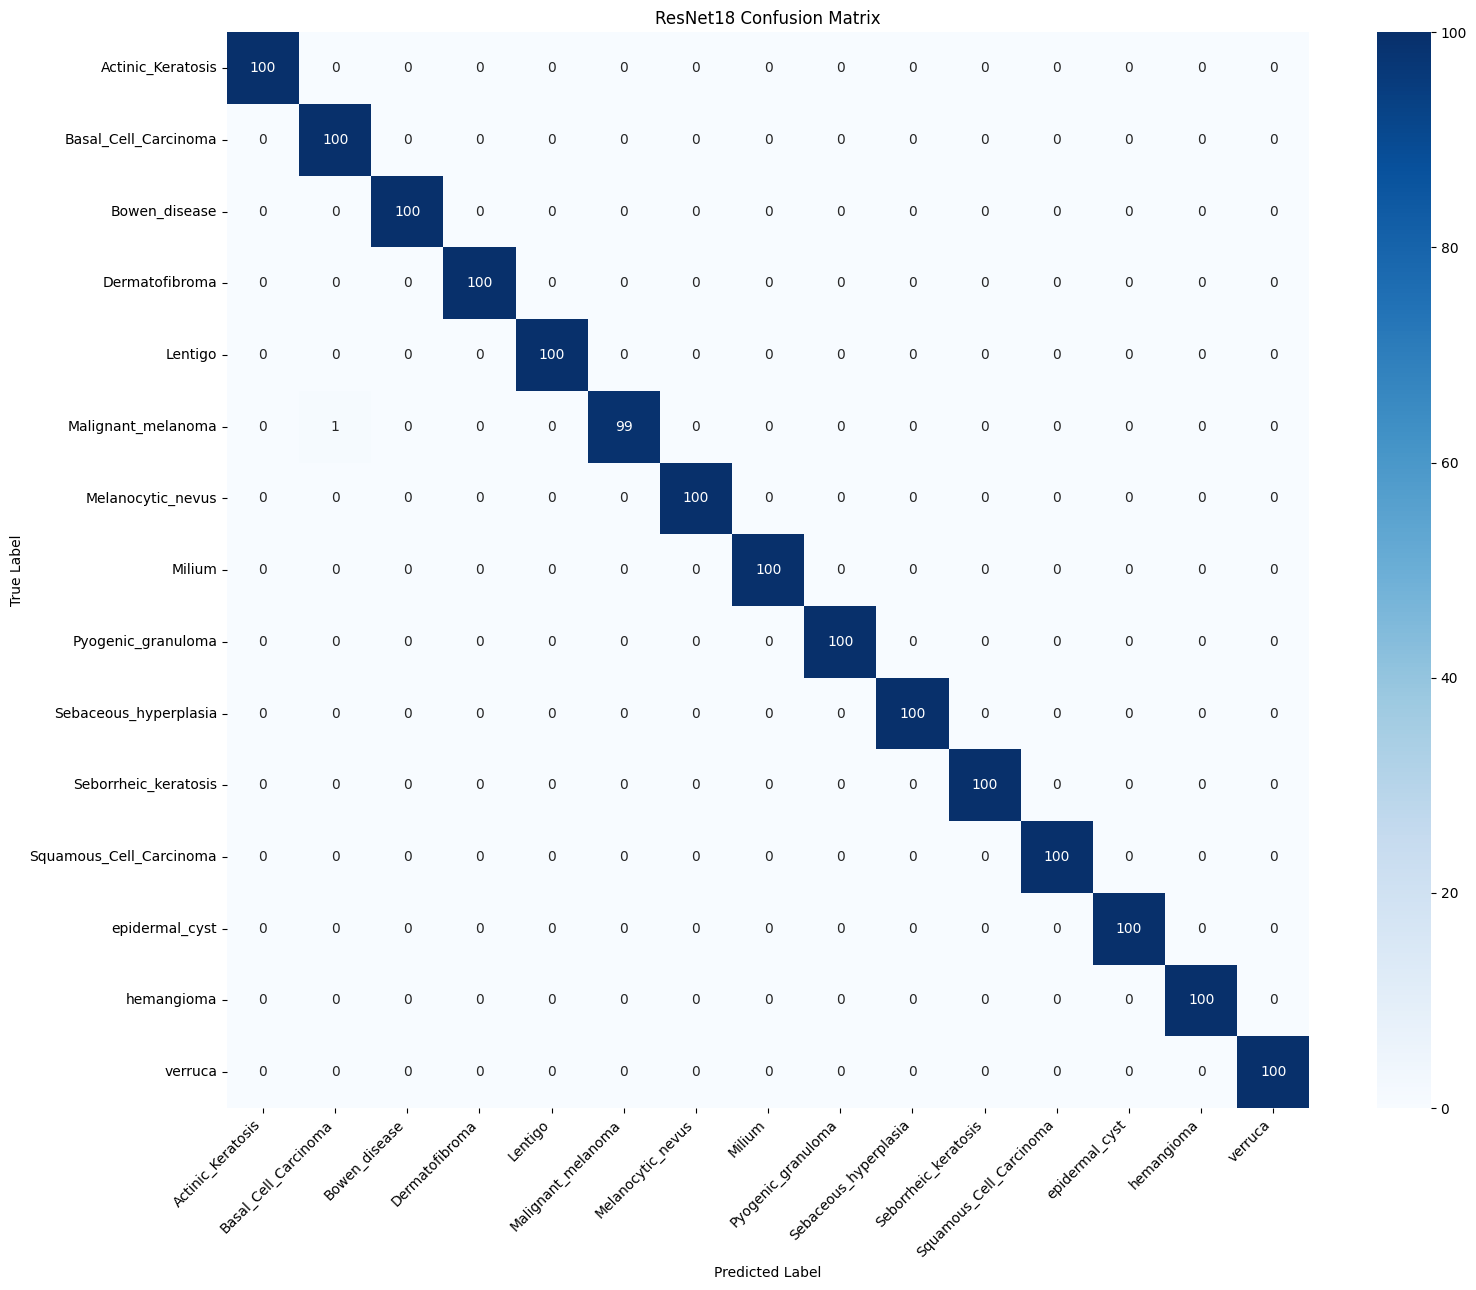

In [15]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(16, 13))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=train_dataset.classes,
    yticklabels=train_dataset.classes
)

plt.title("ResNet18 Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [16]:
print("===== ResNet18 Evaluation =====")

print("Accuracy:",
      accuracy_score(y_true, y_pred))

print("Precision (Macro):",
      precision_score(y_true, y_pred, average="macro", zero_division=0))

print("Recall (Macro):",
      recall_score(y_true, y_pred, average="macro", zero_division=0))

print("F1-score (Macro):",
      f1_score(y_true, y_pred, average="macro", zero_division=0))

print("\n===== Classification Report =====")

print(classification_report(
    y_true,
    y_pred,
    target_names=train_dataset.classes,
    zero_division=0
))

===== ResNet18 Evaluation =====
Accuracy: 0.9993333333333333
Precision (Macro): 0.9993399339933994
Recall (Macro): 0.9993333333333333
F1-score (Macro): 0.99933331666625

===== Classification Report =====
                         precision    recall  f1-score   support

      Actinic_Keratosis       1.00      1.00      1.00       100
   Basal_Cell_Carcinoma       0.99      1.00      1.00       100
          Bowen_disease       1.00      1.00      1.00       100
         Dermatofibroma       1.00      1.00      1.00       100
                Lentigo       1.00      1.00      1.00       100
     Malignant_melanoma       1.00      0.99      0.99       100
      Melanocytic_nevus       1.00      1.00      1.00       100
                 Milium       1.00      1.00      1.00       100
     Pyogenic_granuloma       1.00      1.00      1.00       100
  Sebaceous_hyperplasia       1.00      1.00      1.00       100
   Seborrheic_keratosis       1.00      1.00      1.00       100
Squamous_Cell_C

In [17]:
import os
import hashlib
from collections import Counter

def get_image_hashes(folder):
    hashes = []

    for root, dirs, files in os.walk(folder):
        for file in files:
            if file.lower().endswith((".png", ".jpg", ".jpeg")):
                path = os.path.join(root, file)

                with open(path, "rb") as f:
                    file_hash = hashlib.md5(f.read()).hexdigest()

                hashes.append((file_hash, path))

    return hashes


train_hashes = get_image_hashes(TRAIN_PATH)
val_hashes = get_image_hashes(VAL_PATH)

train_hash_set = set(h for h, p in train_hashes)
val_hash_set = set(h for h, p in val_hashes)

# Training과 Validation 사이의 중복
duplicate_hashes = train_hash_set & val_hash_set

print("Training 이미지:", len(train_hashes))
print("Validation 이미지:", len(val_hashes))
print("Training 내부 고유 이미지:", len(train_hash_set))
print("Validation 내부 고유 이미지:", len(val_hash_set))
print("Training-Validation 중복 이미지:", len(duplicate_hashes))

Training 이미지: 12000
Validation 이미지: 1500
Training 내부 고유 이미지: 11949
Validation 내부 고유 이미지: 1499
Training-Validation 중복 이미지: 16


In [18]:
from collections import defaultdict
import os

train_hash_map = defaultdict(list)
val_hash_map = defaultdict(list)

for h, path in train_hashes:
    train_hash_map[h].append(path)

for h, path in val_hashes:
    val_hash_map[h].append(path)

print("===== Training 내부 중복 =====")

for h, paths in train_hash_map.items():
    if len(paths) > 1:
        print(f"\n중복 수: {len(paths)}")
        print(*paths, sep="\n")

print("\n===== Validation 내부 중복 =====")

for h, paths in val_hash_map.items():
    if len(paths) > 1:
        print(f"\n중복 수: {len(paths)}")
        print(*paths, sep="\n")

print("\n===== Training-Validation 중복 =====")

for h in train_hash_set & val_hash_set:
    print("\nTraining:", train_hash_map[h])
    print("Validation:", val_hash_map[h])

===== Training 내부 중복 =====

중복 수: 2
/content/drive/MyDrive/data/data/Training/Actinic_Keratosis/Z4_5763_P0_L0.png
/content/drive/MyDrive/data/data/Training/Actinic_Keratosis/Z4_5772_P0_L0.png

중복 수: 2
/content/drive/MyDrive/data/data/Training/Actinic_Keratosis/Z4_4489_P0_L0.png
/content/drive/MyDrive/data/data/Training/Actinic_Keratosis/Z4_4486_P0_L0.png

중복 수: 2
/content/drive/MyDrive/data/data/Training/Actinic_Keratosis/Z4_5284_P0_L0.png
/content/drive/MyDrive/data/data/Training/Actinic_Keratosis/Z4_4641_P0_L0.png

중복 수: 2
/content/drive/MyDrive/data/data/Training/Basal_Cell_Carcinoma/Z4_9970_P0_L0.png
/content/drive/MyDrive/data/data/Training/Basal_Cell_Carcinoma/Z4_11885_P0_L0.png

중복 수: 2
/content/drive/MyDrive/data/data/Training/Basal_Cell_Carcinoma/Z4_12526_P0_L0.png
/content/drive/MyDrive/data/data/Training/Basal_Cell_Carcinoma/Z4_12215_P0_L0.png

중복 수: 2
/content/drive/MyDrive/data/data/Training/Basal_Cell_Carcinoma/Z4_9013_P0_L0.png
/content/drive/MyDrive/data/data/Training/B